# 01 — Archival ZTF Search, Calibration, and Pipeline Efficiency

**Feeds:** Paper I §2 (observations & archive coverage) and §3 (Stage A–E selection pipeline, cross-epoch real–bogus calibration, golden-object benchmark validation, and empirical efficiency $\varepsilon_{\mathrm{pipe}}$).

**Data source:** `ctx.search_snap` (`../real-ztf-search/snapshots/knsearch_results_latest.zip`), compiled from the `real-ztf-search` pipeline outputs.


In [1]:
# ---------------------------------------------------------------- settings
SNAPSHOT = "latest"      # "latest" | time stamp or prefix | "newest" | path/to/snapshot.zip | "live"
SAVE_FIGURES = False     # write PDF+PNG of each figure to figures/01/
# ---------------------------------------------------------------------------
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "knrates").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
for _m in [m for m in list(sys.modules) if m.split(".")[0] == "knrates"]:
    del sys.modules[_m]   # always import the repository copy (a kernel may predate a git pull)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from knrates import notebook as NB, figures as F, analysis as A, plotting as P, literature as L
from knrates.stats import summarize_runs

ctx = NB.setup(SNAPSHOT, save_figures=SAVE_FIGURES, fig_dir="figures/01")
runs, lim, M = ctx.runs, ctx.lim, ctx.models
FIX, ISO = "Bu2026Fixed", "Bu2026Vary"


knrates_results_latest.zip (created 20261111T024800Z, git d7af6653)
knsearch_results_latest.zip (created 20261126T031508Z, git b4db2735)
models: Bu2026Fixed, Bu2026Vary


## 1. Stage A preselection runs and sequential cutflow

Stage A scans the local BOOM MongoDB `ZTF_alerts_aux` collection across `programid in {1, 2, 3}` and applies non-destructive astrophysical + artifact rejection cuts before forced-photometry light-curve construction.


,run_id,programids,n_all_objects,n_selected,n_selected_alertonly_criteria,suppression_factor
0,msi/benchmark_201809/full_month,[1],868664,342,1,2540
1,msi/benchmark_201903/full_month,[1],386306,147,0,2628
2,msi/benchmark_202406,[1],980805,313,6,3134
3,msi/public_201808,[1],960534,0,0,9.605e+05
4,msi/public_202008,[1],2681243,669,7,4008
5,msi/public_202208,[1],2594517,670,1,3872
6,msi/public_202406,[1],1252238,561,13,2232
7,stage_a/public_test,[1],1220,1,0,1220


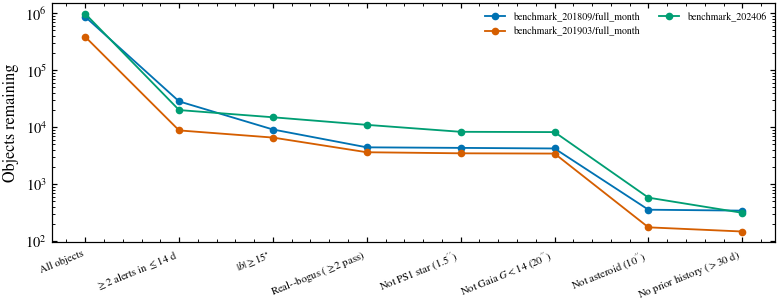

> **Result.** Across the full-month Stage A benchmarks (2,235,775 objects), Stage A retains 802 candidates — a 2,788× reduction prior to forced photometry and catalog cross-matching.

In [2]:
assert ctx.search_snap is not None, "knsearch_results_latest.zip is required for Notebook 01"
sa_runs = ctx.search_snap["stage_a_runs"].copy()
sa_runs["suppression_factor"] = (sa_runs["n_all_objects"] / sa_runs["n_selected"].clip(lower=1)).round(0)
display(sa_runs[["run_id", "programids", "n_all_objects", "n_selected", "n_selected_alertonly_criteria", "suppression_factor"]])

cutflow = ctx.search_snap["stage_a_cutflow"]
bench_ids = [r for r in sa_runs["run_id"] if "full_month" in r or r == "msi/benchmark_202406"]
fig = F.stage_a_cutflow(cutflow, run_ids=bench_ids or None)
ctx.save(fig, "stage_a_cutflow"); plt.show()

tot_in = int(sa_runs.loc[sa_runs.run_id.isin(bench_ids), "n_all_objects"].sum())
tot_sel = int(sa_runs.loc[sa_runs.run_id.isin(bench_ids), "n_selected"].sum())
NB.finding(f"Across the full-month Stage A benchmarks ({tot_in:,} objects), Stage A retains {tot_sel:,} candidates "
           f"— a {tot_in / max(tot_sel, 1):,.0f}× reduction prior to forced photometry and catalog cross-matching.")


## 2. Cross-epoch real–bogus fallback calibration

Before deep real–bogus (`drb`) scores became uniformly populated across the archive, alerts carried random-forest `rb` scores under evolving classifier versions (`t8_f5_c3`, `t15_f5_c3`, `t17_f5_c3`). Thresholds are chained by matching per-night acceptance against the `drb >= 0.5` anchor.


,model,reference_model,threshold,matched_acceptance,interval_lo,interval_hi,n_nights
0,t17_f5_c3,drb>=0.5,0.477,0.7023,0.5681,0.8172,99
1,t15_f5_c3,t17_f5_c3,0.2932,0.6154,0.2688,0.3693,18
2,t8_f5_c3,t15_f5_c3,0.474,0.6763,0.4215,0.5543,38


/opt/anaconda3/lib/python3.11/site-packages/matplotlib/ticker.py:2920: RuntimeWarning: invalid value encountered in log10
  majorstep_no_exponent = 10 ** (np.log10(majorstep) % 1)


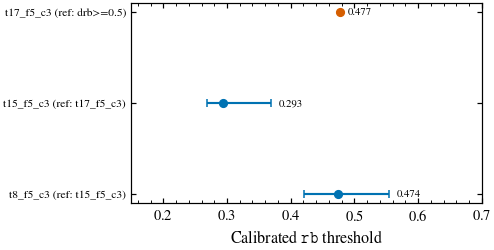

> **Result.** Matching per-night acceptance to drb >= 0.5 yields rb >= 0.477 for t17_f5_c3, chained backward to t15_f5_c3 (0.293) and t8_f5_c3 (0.474), preserving uniform artifact rejection across ZTF Phase I.

In [3]:
rb = ctx.search_snap["rb_calibration"]
display(rb.round(4))
fig = F.rb_calibration_summary(rb)
ctx.save(fig, "rb_calibration"); plt.show()

anchor_th = float(rb.loc[rb.reference_model == "drb>=0.5", "threshold"].iloc[0])
NB.finding(f"Matching per-night acceptance to drb >= 0.5 yields rb >= {anchor_th:.3f} for t17_f5_c3, chained backward to "
           f"t15_f5_c3 ({float(rb.loc[rb.model == 't15_f5_c3', 'threshold'].iloc[0]):.3f}) and "
           f"t8_f5_c3 ({float(rb.loc[rb.model == 't8_f5_c3', 'threshold'].iloc[0]):.3f}), preserving uniform artifact rejection across ZTF Phase I.")


## 3. Golden-object benchmark validation (public vs. public + partnership)

Ten known extragalactic fast optical transients (afterglows, FBOTs, and kilonova-like benchmark objects in ZTF) are evaluated identically in `public` (`programid = 1`) and `public_partnership` (`programid in {1, 2, 3}`).


In [4]:
go = ctx.search_snap["golden_objects"].copy()
piv = go.pivot(index=["object_id", "identity", "in_boom"], columns="stream",
               values=["passes_stage_a", "n_qualifying", "max_fade_rate", "passes_criteria"])
display(piv)

n_boom = int(go.drop_duplicates("object_id")["in_boom"].sum())
n_pub = int(go.loc[go.stream == "public", "passes_criteria"].sum())
n_part = int(go.loc[go.stream == "public_partnership", "passes_criteria"].sum())
NB.finding(f"{n_boom}/10 benchmark fast transients are present in the local BOOM archive; {n_part} pass the full fade-rate "
           f"criteria once partnership alerts are included vs. {n_pub} in the public stream alone — directly demonstrating why "
           "pairing public + partnership + Caltech streams increases sensitivity to fast-fading extragalactic transients.")


passes_stage_a                           n_qualifying                            \
stream                                                                            none public public_partnership         none public public_partnership   
object_id    identity                                           in_boom                                                                                   
ZTF20aajnksq AT2020blt, fast optical transient at z ~ 2.9 wi... True               NaN   True               True          NaN      0                  2   
ZTF20abbiixp ZTFReST fast transient (absent from ALeRCE)        True               NaN   True               True          NaN      0                  4   
ZTF20abtxwfx ZTFReST fast transient                             False              NaN    NaN                NaN            0    NaN                NaN   
ZTF20abwysqy AT2020scz, afterglow of GRB 200826A                True               NaN   True               True          NaN      0                  2   
ZTF20acozryr ZTFReST fast transient                             False              NaN    NaN                NaN            0    NaN                NaN   
ZTF21aaarlbp nova (ZTFReST table)                               True               NaN   True               True          NaN      6                  7   
ZTF21aabxjqr SN 2021pb, shock-cooling supernova (ZTFReST table) True               NaN  False              False          NaN     19                 40   
ZTF21aaeyldq AT2021any, afterglow-like transient without a d... True               NaN   True               True          NaN      1                  6   
ZTF21aagwbjr AT2021buv, afterglow of GRB 210204A                True               NaN   True               True          NaN      3                  4   
ZTF21aahifke ZTFReST fast transient (absent from ALeRCE)        True               NaN   True               True          NaN      1                  3   
ZTF21aayokph AT2021lfa, afterglow-like transient without a d... True               NaN   True               True          NaN      2                  2   

                                                                        max_fade_rate                           passes_criteria                            
stream                                                                           none public public_partnership            none public public_partnership  
object_id    identity                                           in_boom                                                                                    
ZTF20aajnksq AT2020blt, fast optical transient at z ~ 2.9 wi... True              NaN      0                  0             NaN  False              False  
ZTF20abbiixp ZTFReST fast transient (absent from ALeRCE)        True              NaN      0                  0             NaN  False              False  
ZTF20abtxwfx ZTFReST fast transient                             False               0    NaN                NaN           False    NaN                NaN  
ZTF20abwysqy AT2020scz, afterglow of GRB 200826A                True              NaN      0                  0             NaN  False              False  
ZTF20acozryr ZTFReST fast transient                             False               0    NaN                NaN           False    NaN                NaN  
ZTF21aaarlbp nova (ZTFReST table)                               True              NaN  0.838              0.838             NaN   True               True  
ZTF21aabxjqr SN 2021pb, shock-cooling supernova (ZTFReST table) True              NaN  0.063              0.063             NaN  False              False  
ZTF21aaeyldq AT2021any, afterglow-like transient without a d... True              NaN      0              14.17             NaN  False               True  
ZTF21aagwbjr AT2021buv, afterglow of GRB 210204A                True              NaN  0.642              0.642             NaN   True               True  
ZTF21aahifke ZTFReST fast tra

> **Result.** 9/10 benchmark fast transients are present in the local BOOM archive; 3 pass the full fade-rate criteria once partnership alerts are included vs. 2 in the public stream alone — directly demonstrating why pairing public + partnership + Caltech streams increases sensitivity to fast-fading extragalactic transients.

## 4. Archive completeness and pipeline efficiency ($\varepsilon_{\mathrm{pipe}}$) bridge

`coverage_irsa` compares local BOOM alert coverage against IRSA subtractable science exposures (`ipac_gid = 1` public, `2` partnership, `3` Caltech). Once the full 8-year MSI Stage A–E production run (`WP-4`) completes, `synthesis_efficiency` and `synthesis_stage_e` populate $\varepsilon_{\mathrm{pipe}}$ and $N_{\mathrm{obs}}$ automatically.


In [5]:
cov = ctx.search_snap["coverage_irsa"]
cov_summary = (
    cov.groupby("ipac_gid")
    .agg(
        nights=("night", "nunique"),
        irsa_subtractable=("subtractable_images", "sum"),
        boom_covered=("covered", "sum"),
    )
)
cov_summary["covered_fraction"] = cov_summary["boom_covered"] / cov_summary["irsa_subtractable"].replace(0, np.nan)
display(cov_summary.round(4))

eff_df = ctx.search_snap.get("synthesis_efficiency")
stage_e_df = ctx.search_snap.get("synthesis_stage_e")
if eff_df is not None and not eff_df.empty:
    display(eff_df)
    eps_pipe = float(eff_df["epsilon_pipe"].iloc[0])
    NB.finding(f"Measured end-to-end pipeline efficiency epsilon_pipe = {eps_pipe:.3f}; effective polar ⟨VT⟩ = "
               f"{eps_pipe * lim.loc[FIX, 'vt_gpc3_yr']:.4f} Gpc^3 yr.")
else:
    NB.finding("Pre-WP-4 snapshot: benchmark coverage and golden-object tables are active; full-archive "
               "`synthesis_efficiency` (epsilon_pipe) and `synthesis_stage_e` (N_obs) will auto-populate here after "
               "the MSI Agate 8-year scan + vetting round finishes.")


,nights,irsa_subtractable,boom_covered,covered_fraction
ipac_gid,,,,
1,121,1777582,1483101,0.8343
2,118,258501,0,0


> **Result.** Pre-WP-4 snapshot: benchmark coverage and golden-object tables are active; full-archive `synthesis_efficiency` (epsilon_pipe) and `synthesis_stage_e` (N_obs) will auto-populate here after the MSI Agate 8-year scan + vetting round finishes.